# DSA2050 - WEEK 11 LAB

## Model Selection and Defensible Evaluation

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance
import sklearn

#Fetching the dataset we are using from github
github_raw_url = 'https://raw.githubusercontent.com/tmwakisha/DSA2050-Week11-GroupWork/refs/heads/main/data/churn_development.csv'

#Loading the dataset
df = pd.read_csv(github_raw_url)

#Displaying the first five customer records
display(df.head())

,customer_id,tenure_months,monthly_charges_kes,support_tickets_90d,service_calls_90d,plan_type,region,autopay,customer_segment,cancellation_confirmed,churn
0,CUST-12486,22,1943.94,1.0,2,Basic,Mombasa,Yes,Established,Active,0
1,CUST-12546,40,5003.13,1.0,0,Premium,Nairobi,No,Established,Active,0
2,CUST-11112,57,2796.23,1.0,1,Basic,Nairobi,Yes,Established,Active,0
3,CUST-12753,33,4697.39,NaN,0,Premium,Nairobi,Yes,Established,Active,0
4,CUST-10753,53,4330.27,2.0,1,Standard,Mombasa,No,Established,Active,0


## Data check

In [2]:
print('Development data shape:', df.shape)
print('Churn balance:')
print(df['churn'].value_counts(normalize=True).rename('proportion').round(3))
print('Missing values:')
print(df.isna().sum())
print('Unit of analysis: one customer record')
print('Target: churn, where 1 means cancelled and 0 means stayed')

# Dropping the customer ID and the post-outcome leakage field before modelling.
TARGET = 'churn'
X_dev = df.drop(columns=['churn', 'customer_id', 'cancellation_confirmed'])
y_dev = df[TARGET].astype(int)

print('Features used:', X_dev.columns.tolist())
print('Leakage check: cancellation_confirmed is excluded because it is known after cancellation.')

Development data shape: (2720, 11)
Churn balance:
churn
0    0.665
1    0.335
Name: proportion, dtype: float64
Missing values:
customer_id                 0
tenure_months               0
monthly_charges_kes       156
support_tickets_90d       120
service_calls_90d           0
plan_type                   0
region                     93
autopay                     0
customer_segment            0
cancellation_confirmed      0
churn                       0
dtype: int64
Unit of analysis: one customer record
Target: churn, where 1 means cancelled and 0 means stayed
Features used: ['tenure_months', 'monthly_charges_kes', 'support_tickets_90d', 'service_calls_90d', 'plan_type', 'region', 'autopay', 'customer_segment']
Leakage check: cancellation_confirmed is excluded because it is known after cancellation.


## Preprocessing and cross-validation

In [3]:
num_cols = X_dev.select_dtypes(include='number').columns.tolist()
cat_cols = X_dev.select_dtypes(exclude='number').columns.tolist()

# Imputation and encoding are fitted separately inside each training fold.
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
category_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', category_pipe, cat_cols)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Numeric features:', num_cols)
print('Categorical features:', cat_cols)
print('CV setup:', cv)

Numeric features: ['tenure_months', 'monthly_charges_kes', 'support_tickets_90d', 'service_calls_90d']
Categorical features: ['plan_type', 'region', 'autopay', 'customer_segment']
CV setup: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


## Baseline and model comparison

In [4]:
from sklearn.metrics import make_scorer

scoring = {
    'f1': 'f1',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': 'recall'
}

dummy_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent'))
])
dummy_scores = cross_validate(dummy_pipeline, X_dev, y_dev, cv=cv, scoring=scoring)
print('Dummy baseline fold F1:', np.round(dummy_scores['test_f1'], 3))
print('Dummy baseline mean F1:', round(dummy_scores['test_f1'].mean(), 3))

candidates = {
    'Logistic regression': (
        LogisticRegression(max_iter=2000, random_state=42),
        {'model__C': [0.1, 1, 10]}
    ),
    'Decision tree': (
        DecisionTreeClassifier(random_state=42),
        {'model__max_depth': [3, 5, 8]}
    )
}

searches = {}
rows = []
for name, (model, grid) in candidates.items():
    pipeline = Pipeline([('prep', preprocessor), ('model', model)])
    search = GridSearchCV(
        pipeline, grid, cv=cv, scoring=scoring, refit='f1',
        n_jobs=1, return_train_score=True
    )
    search.fit(X_dev, y_dev)
    searches[name] = search

    for _, result in pd.DataFrame(search.cv_results_).iterrows():
        row = {
            'model': name,
            'settings': str(result['params']),
            'mean_f1': float(result['mean_test_f1']),
            'std_f1': float(result['std_test_f1']),
            'mean_precision': float(result['mean_test_precision']),
            'mean_recall': float(result['mean_test_recall'])
        }
        for fold in range(5):
            row[f'fold_{fold + 1}_f1'] = float(result[f'split{fold}_test_f1'])
        rows.append(row)

experiment_log = pd.DataFrame(rows).sort_values('mean_f1', ascending=False)
REPORTS = Path('reports')
REPORTS.mkdir(exist_ok=True)
experiment_log.to_csv(REPORTS / 'experiment_log.csv', index=False)
display(experiment_log.round(3))

Dummy baseline fold F1: [0. 0. 0. 0. 0.]
Dummy baseline mean F1: 0.0


,model,settings,mean_f1,std_f1,mean_precision,mean_recall,fold_1_f1,fold_2_f1,fold_3_f1,fold_4_f1,fold_5_f1
1,Logistic regression,{'model__C': 1},0.470,0.053,0.624,0.378,0.391,0.534,0.472,0.434,0.519
2,Logistic regression,{'model__C': 10},0.470,0.053,0.624,0.378,0.391,0.534,0.472,0.434,0.519
0,Logistic regression,{'model__C': 0.1},0.465,0.054,0.625,0.371,0.388,0.533,0.454,0.432,0.519
3,Decision tree,{'model__max_depth': 3},0.398,0.049,0.566,0.318,0.392,0.457,0.316,0.437,0.391
4,Decision tree,{'model__max_depth': 5},0.382,0.023,0.583,0.287,0.376,0.383,0.365,0.362,0.426
5,Decision tree,{'model__max_depth': 8},0.372,0.051,0.495,0.300,0.298,0.439,0.338,0.370,0.417


## Model choice

In [5]:
best_by_model = (
    experiment_log.sort_values('mean_f1', ascending=False, kind='stable')
    .drop_duplicates(subset='model')
    .reset_index(drop=True)
)
display(best_by_model[['model', 'mean_f1', 'std_f1', 'mean_precision', 'mean_recall']].round(3))

# Use the top CV model and keep its tuned settings.
CHOSEN_MODEL = best_by_model.iloc[0]['model']
chosen_search = searches[CHOSEN_MODEL]
chosen_pipeline = chosen_search.best_estimator_
print('Selected model:', CHOSEN_MODEL)
print('Selected settings:', chosen_search.best_params_)
print('Mean CV F1:', round(chosen_search.best_score_, 4))

,model,mean_f1,std_f1,mean_precision,mean_recall
0,Logistic regression,0.470,0.053,0.624,0.378
1,Decision tree,0.398,0.049,0.566,0.318


Selected model: Logistic regression
Selected settings: {'model__C': 1}
Mean CV F1: 0.4701


## Errors and subgroup results

              precision    recall  f1-score   support

           0       0.74      0.89      0.81      1810
           1       0.63      0.38      0.47       910

    accuracy                           0.72      2720
   macro avg       0.68      0.63      0.64      2720
weighted avg       0.70      0.72      0.69      2720



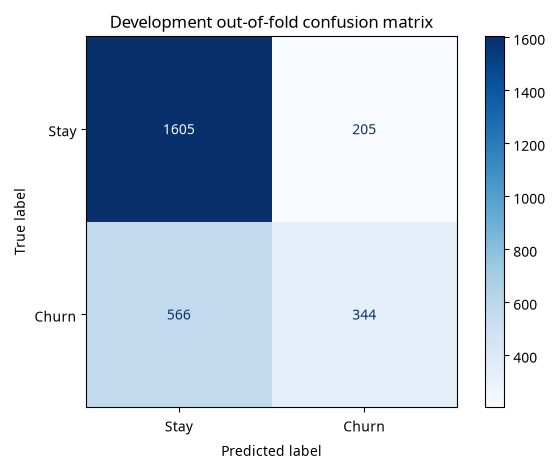

Error counts:
error_type
Correct           1949
False negative     566
False positive     205
Name: count, dtype: int64


,segment,n_customers,n_actual_churn,recall,precision,false_negatives
0,Established,2268,649,0.216,0.593,509
1,New,452,261,0.782,0.652,57


In [6]:
oof_pred = cross_val_predict(chosen_pipeline, X_dev, y_dev, cv=cv, method='predict')
print(classification_report(y_dev, oof_pred, zero_division=0))

cm = confusion_matrix(y_dev, oof_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['Stay', 'Churn']).plot(cmap='Blues')
plt.title('Development out-of-fold confusion matrix')
plt.tight_layout()
plt.savefig(REPORTS / 'development_confusion_matrix.png', dpi=150)
plt.show()

errors = df[['customer_id', 'customer_segment', 'churn']].copy()
errors['prediction'] = oof_pred
errors['error_type'] = np.select(
    [(errors['churn'] == 1) & (errors['prediction'] == 0),
     (errors['churn'] == 0) & (errors['prediction'] == 1)],
    ['False negative', 'False positive'],
    default='Correct'
)
print('Error counts:')
print(errors['error_type'].value_counts())

group_rows = []
for segment, part in errors.groupby('customer_segment'):
    truth = part['churn'].to_numpy()
    pred = part['prediction'].to_numpy()
    group_rows.append({
        'segment': segment,
        'n_customers': len(part),
        'n_actual_churn': int(truth.sum()),
        'recall': recall_score(truth, pred, zero_division=0),
        'precision': precision_score(truth, pred, zero_division=0),
        'false_negatives': int(((truth == 1) & (pred == 0)).sum())
    })
subgroup = pd.DataFrame(group_rows)
subgroup.to_csv(REPORTS / 'subgroup_metrics.csv', index=False)
display(subgroup.round(3))

## Permutation importance

,feature,importance_mean,importance_std
0,tenure_months,0.079,0.024
2,support_tickets_90d,0.035,0.016
7,customer_segment,0.018,0.006
1,monthly_charges_kes,0.016,0.023
4,plan_type,0.015,0.015
5,region,0.006,0.013
3,service_calls_90d,0.003,0.007
6,autopay,0.002,0.017


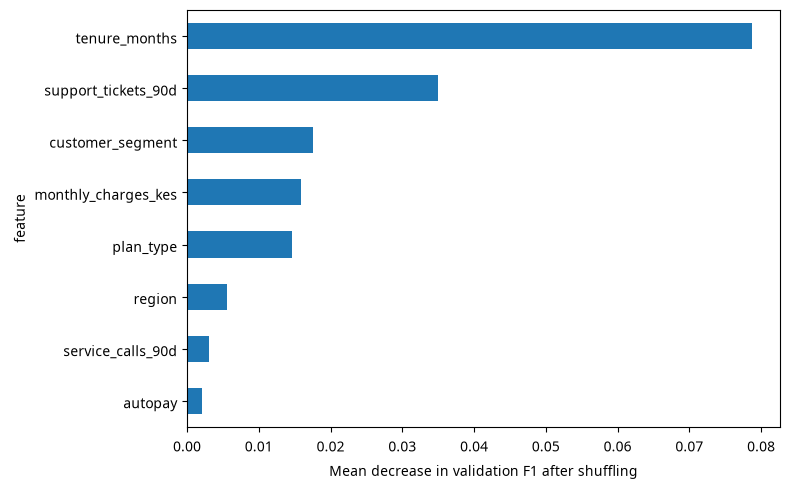

In [7]:
X_inner, X_validation, y_inner, y_validation = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=2050, stratify=y_dev
)
importance_model = chosen_pipeline.fit(X_inner, y_inner)
importance = permutation_importance(
    importance_model, X_validation, y_validation,
    scoring='f1', n_repeats=5, random_state=42, n_jobs=1
)
importance_table = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean': importance.importances_mean,
    'importance_std': importance.importances_std
}).sort_values('importance_mean', ascending=False)
importance_table.to_csv(REPORTS / 'permutation_importance.csv', index=False)
display(importance_table.round(3))

ax = importance_table.sort_values('importance_mean').plot.barh(
    x='feature', y='importance_mean', legend=False, figsize=(8, 5)
)
ax.set_xlabel('Mean decrease in validation F1 after shuffling')
plt.tight_layout()
plt.savefig(REPORTS / 'permutation_importance.png', dpi=150)
plt.show()

## Freeze the selection

In [8]:
best_logistic = best_by_model.loc[best_by_model['model'] == 'Logistic regression'].iloc[0]
best_tree = best_by_model.loc[best_by_model['model'] == 'Decision tree'].iloc[0]
selected_row = best_by_model.loc[best_by_model['model'] == CHOSEN_MODEL].iloc[0]
false_negatives = int(((y_dev == 1) & (oof_pred == 0)).sum())
established_recall = float(subgroup.loc[subgroup['segment'] == 'Established', 'recall'].iloc[0])
new_recall = float(subgroup.loc[subgroup['segment'] == 'New', 'recall'].iloc[0])

RATIONALE = (
    f"{CHOSEN_MODEL} was selected with settings {chosen_search.best_params_}. It achieved mean CV F1 "
    f"{selected_row['mean_f1']:.4f} (SD {selected_row['std_f1']:.4f}), compared with the best tree's "
    f"mean F1 {best_tree['mean_f1']:.4f} (SD {best_tree['std_f1']:.4f}). The stronger average score supports "
    f"the choice, although fold variation is slightly higher. Out-of-fold predictions include {false_negatives} "
    f"false negatives. Recall was {established_recall:.4f} for Established customers and {new_recall:.4f} "
    f"for New customers, so this difference is considered before testing. Logistic regression is also a "
    f"relatively simple model. This supports the choice among the tested candidates, but does not establish "
    f"deployment readiness."
)

freeze = {
    'selected_model': CHOSEN_MODEL,
    'best_params': chosen_search.best_params_,
    'primary_metric': 'f1',
    'cv_mean_f1': float(chosen_search.best_score_),
    'rationale': RATIONALE,
    'random_seed': 42,
    'scikit_learn_version': sklearn.__version__
}
(REPORTS / 'frozen_selection.json').write_text(json.dumps(freeze, indent=2), encoding='utf-8')
print(RATIONALE)
print('Selection saved before the final test.')

Logistic regression was selected with settings {'model__C': 1}. It achieved mean CV F1 0.4701 (SD 0.0527), compared with the best tree's mean F1 0.3985 (SD 0.0487). The stronger average score supports the choice, although fold variation is slightly higher. Out-of-fold predictions include 566 false negatives. Recall was 0.2157 for Established customers and 0.7816 for New customers, so this difference is considered before testing. Logistic regression is also a relatively simple model. This supports the choice among the tested candidates, but does not establish deployment readiness.
Selection saved before the final test.


## Final test

In [ ]:
# This cell reads the final-test CSV only after the selection has been frozen.
final_path = REPORTS / 'final_metrics.json'
assert (REPORTS / 'frozen_selection.json').exists(), 'Freeze the model choice first.'

if final_path.exists():
    final_metrics = json.loads(final_path.read_text(encoding='utf-8'))
    print('Saved final metrics:')
    print(json.dumps(final_metrics, indent=2))
else:
    final_test_url = 'https://raw.githubusercontent.com/tmwakisha/DSA2050-Week11-GroupWork/refs/heads/main/data/churn_final_test.csv'
    final_test = pd.read_csv(final_test_url)
    X_test = final_test.drop(columns=['churn', 'customer_id', 'cancellation_confirmed'])
    y_test = final_test['churn'].astype(int)

    final_model = chosen_search.best_estimator_
    final_model.fit(X_dev, y_dev)
    final_pred = final_model.predict(X_test)
    final_cm = confusion_matrix(y_test, final_pred, labels=[0, 1])

    final_metrics = {
        'model': CHOSEN_MODEL,
        'n_test': int(len(y_test)),
        'cv_mean_f1': round(float(chosen_search.best_score_), 4),
        'test_accuracy': round(float(accuracy_score(y_test, final_pred)), 4),
        'test_f1': round(float(f1_score(y_test, final_pred, zero_division=0)), 4),
        'test_precision': round(float(precision_score(y_test, final_pred, zero_division=0)), 4),
        'test_recall': round(float(recall_score(y_test, final_pred, zero_division=0)), 4),
        'confusion_matrix_0_1': final_cm.tolist()
    }
    final_path.write_text(json.dumps(final_metrics, indent=2), encoding='utf-8')
    print(json.dumps(final_metrics, indent=2))

# The matrix is displayed for both newly calculated and saved metrics.
ConfusionMatrixDisplay(np.array(final_metrics['confusion_matrix_0_1']), display_labels=['Stay', 'Churn']).plot(cmap='Blues')
plt.title('Final test confusion matrix')
plt.tight_layout()
plt.show()


## Reflection

1. **Which model was selected and why was it defensible? Include mean F1 and fold standard deviation.**

   Logistic regression (`C=1`) achieved mean F1 0.4701 (SD 0.0527), compared with 0.3985 (SD 0.0487) for the best decision tree. The higher average F1 and recall support the choice, although the fold variation was slightly higher.

2. **What did false negatives mean for this provider? Which subgroup struggled most?**

   False negatives are churners predicted to stay, which could mean a missed chance to offer retention support. Established customers had the lowest recall, 0.2157, with 509 of 649 churners missed.

3. **Which feature was highest in permutation importance, and why does that not imply causation?**

   `tenure_months` was highest. Shuffling it reduced validation F1 the most, but this shows model reliance, not that tenure causes churn. Correlated features can share or mask importance.

4. **Compare final-test F1 with mean CV F1. Did your model generalize reasonably?**

   Final-test F1 was 0.4486 versus mean CV F1 of 0.4701, a difference of 0.0215. That is broadly consistent, but recall was low and the model missed 145 churners, so further validation would be needed before real use.

5. **State two limitations of this synthetic dataset and one step you would take before deploying a real churn model.**

   The synthetic records may not reflect real customer behaviour, and the data do not establish real feature timing or intervention costs. Before deployment, validate on representative, time-separated real customer data and check feature availability and subgroup performance.